In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from optimizer import grid_search, strategy_compare

In [3]:
STRATEGIES = {
    "BuyHold": {"classic_dca": True},
    "Default": {},
    "Experimental1": {"cooldown_long": 90},
    "NoConfirm": {"manual_sell_fraction": 0.5, "minimum_profit": 2.0},
    "Experimental2": {"cooldown_long": 90, "manual_sell_fraction": 0.5, "minimum_profit": 2.0},
}

In [4]:
df_prices = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_prices

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


# COMPARE

In [5]:
history_compare = strategy_compare(
    prices=df_prices,
    strategies=STRATEGIES,
    n_boot=100,
    sample_size=10,
    sequence_length=365 * 4,
)

100%|██████████| 5/5 [04:16<00:00, 51.29s/it]


In [6]:
history_compare

,strategy,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MA200_survival_days,RoAC,iteration
0,BuyHold,BTC,2059,0,4829,2059,4829,90,21630.373664,0,-2448,101.000000,94,1
1,BuyHold,SOL,2069,0,29951,2069,29951,96,10.126949,0,-41052,138.200000,982,1
2,BuyHold,LINK,2069,0,4077,2069,4077,44,11.184619,0,-1764,147.000000,-3,1
3,BuyHold,DOT,2069,0,1121,2069,1121,41,7.729390,0,-1827,143.000000,30,1
4,BuyHold,DOT,2069,0,630,2069,630,18,5.060636,0,-1908,58.750000,-21,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,Experimental2,XLM,2455,6880,299,218,7179,36,0.185153,13,-2578,82.714286,284,100
4996,Experimental2,XLM,2187,4543,511,956,5055,54,0.137977,6,-1803,0.000000,428,100
4997,Experimental2,XLM,2267,5936,288,471,6225,46,0.184954,9,-2221,14.000000,462,100
4998,Experimental2,LINK,2158,2373,783,1171,3156,61,9.620081,8,-889,53.500000,296,100


In [11]:
compare_res = history_compare.groupby("strategy").agg(
    RoAC=("RoAC", "mean"),
    MDD=("MDD", "mean"),
    Portfolio=("Portfolio", "mean"),
    Realized_cash=("Realized_cash", "mean"),
    Cash_spent=("Cash_spent", "mean"),
    Total_value_mean=("Total_value", "mean"),
    Total_value_median=("Total_value", "median"),
    Total_value_low=("Total_value", lambda s: np.percentile(s, 25)),
    Total_value_high=("Total_value", lambda s: np.percentile(s, 75)),
)

compare_res['Uncle'] = compare_res['MDD'] / compare_res['Total_value_mean']
compare_res.sort_values("RoAC", ascending=False).style.background_gradient(cmap="RdYlGn", axis=0).format("{:.2f}")

,RoAC,MDD,Portfolio,Realized_cash,Cash_spent,Total_value_mean,Total_value_median,Total_value_low,Total_value_high,Uncle
strategy,,,,,,,,,,
Experimental2,498.09,-3473.34,1057.32,4585.18,2168.08,5642.99,4315.50,3461.75,5699.25,-0.62
NoConfirm,453.28,-953.61,880.41,3587.48,2185.32,4468.34,3970.00,3253.75,4875.00,-0.21
Default,376.20,-708.12,792.38,3365.88,2181.80,4158.76,3687.50,3100.50,4462.75,-0.17
Experimental1,335.29,-3080.16,1567.63,3561.68,2157.28,5129.81,3750.00,3027.25,5413.00,-0.60
BuyHold,274.73,-23041.32,7984.47,0.00,2064.55,7984.47,3650.50,2243.75,7273.00,-2.89


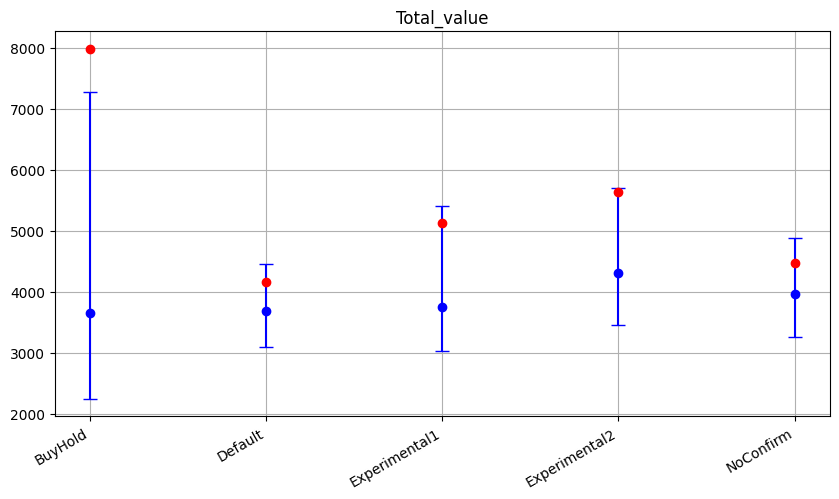

In [12]:
metric = "Total_value"

plt.figure(figsize=(10, 5))

median = compare_res[f"{metric}_median"]
mean = compare_res[f"{metric}_mean"]
low = compare_res[f"{metric}_low"]
high = compare_res[f"{metric}_high"]

plt.errorbar(
    median.index,
    median.values,
    yerr=[median - low, high - median],
    fmt="o",
    capsize=5,
    label="median",
    color="blue",
)
plt.errorbar(
    mean.index,
    mean.values,
    fmt="o",
    capsize=5,
    label="mean",
    color="red",
)
plt.title(metric)
plt.xticks(rotation=30, ha="right")
plt.grid()
plt.show()